# Contribución acumulada de cabezas a la clasificación (2026-08-22)

**Esto no es ablación** (esa quedó en `notebooks/22082026_ablation/`, donde apagamos una cabeza a la vez dejando las demás intactas). Esto es distinto: **conectar la capa de clasificación a un subconjunto creciente de cabezas** de un mismo bloque — cabeza 1 sola, luego cabeza 1+2, luego 1+2+3, luego las 4 — y ver cómo se arma la predicción a medida que se van sumando.

En el `for` sobre las cabezas, en vez de "apagar una", vamos "guardando" las primeras `k` y saltando (poniendo en cero) el resto: con `k=1` saltamos las últimas 3 cabezas, con `k=2` saltamos las últimas 2, con `k=3` saltamos la última, con `k=4` no saltamos ninguna (eso último debe ser idéntico al forward normal — es el sanity check de siempre).

Por defecto lo hacemos sobre el **último bloque** (el que conecta directo con la capa de clasificación — `self.classifier(encoder_output[:, 0, :])`), que es lo que describiste. El resto del bloque (el MLP) sigue corriendo normal — solo se recorta cuántas cabezas de atención participan.

In [1]:
import json
import sys
from pathlib import Path

# Misma convención que el resto de notebooks/: vive 2 niveles bajo la raíz del proyecto.
project_root = Path.cwd().resolve().parents[1]
print(f"Project root: {project_root}")
sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset
from modules.figures import save_fig

torch.manual_seed(0)

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "22082026_head_contribution"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2"
}

Project root: /Users/valefeve/Projects/interpretability of neural networks/interpretable-transformers


## 1. Cargar los dos modelos

`map_location="cpu"` porque los checkpoints se guardaron desde MPS. Igual que en `ablation.ipynb`, esto
asume `use_faster_attention=False` (cabezas como submódulos separados).

In [2]:
def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    with open(exp_dir / "config.json") as f:
        config = json.load(f)
    with open(exp_dir / "metrics.json") as f:
        metrics = json.load(f)
    assert not config["use_faster_attention"], (
        "Este notebook asume block.attention.heads (cabezas separadas); "
        "con use_faster_attention=True habria que adaptar la funcion de abajo."
    )
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    model.eval()
    return model, config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}

config = models["unconstrained"][1]
assert all(m[1] == config for m in models.values()), "Los modelos deben tener la misma arquitectura"
n_blocks = len(models["unconstrained"][0].encoder.blocks)
n_heads = config["num_attention_heads"]

for key, (_, _, metrics) in models.items():
    print(f"{key:>13} ({MODELS[key]}): accuracy de entrenamiento = {metrics['accuracy']:.4f}")
print(f"Bloques: {n_blocks}  |  cabezas por bloque: {n_heads}")

unconstrained (vit-15-AwA2): accuracy de entrenamiento = 0.2971
  constrained (vit-15-constrained-AwA2): accuracy de entrenamiento = 0.2879
constrained_rank (vit-15-constrained_rank-AwA2): accuracy de entrenamiento = 0.2973
Bloques: 4  |  cabezas por bloque: 4


## 2. Datos de test (AwA2)

`AwA2Dataset` usa el cache local ya construido en `data/awa2/`, así que no vuelve a descargar nada.

In [3]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
num_classes = dataset.n_classes

N_EVAL = 500  # tamano del lote de evaluacion (CPU-friendly)
# Muestra aleatoria con semilla fija: el testset de AwA2 viene ordenado por clase, así que las primeras N
# imágenes cubrirían solo unas pocas clases.
eval_images, eval_labels = dataset.get_samples_from_indices(torch.randperm(len(dataset.testset), generator=torch.Generator().manual_seed(0))[:N_EVAL].tolist(), device="cpu", set="test")
print(f"Lote de evaluacion: {N_EVAL} imagenes de test, {num_classes} clases")

Lote de evaluacion: 500 imagenes de test, 50 clases


## 3. La función: cabezas acumuladas dentro de un bloque

`forward_with_heads_kept(model, x, target_layer_idx, n_heads_kept)`: en el bloque `target_layer_idx`, corre cada cabeza por separado (como hace `MultiHeadAttention.forward` internamente) pero solo deja activas las primeras `n_heads_kept` (índices `0..n_heads_kept-1`); el resto se pone en cero antes de concatenar y proyectar. El MLP de ese bloque y todos los bloques siguientes (si los hay) corren normal. Con `n_heads_kept = n_heads` nada se toca — debe reproducir el forward normal exacto.

In [4]:
@torch.no_grad()
def forward_with_heads_kept(model, x, target_layer_idx, n_heads_kept):
    h = model.embedding(x)
    for i, block in enumerate(model.encoder.blocks):
        if i == target_layer_idx:
            attn_in = block.layernorm_1(h)
            head_outputs = []
            for hidx, head in enumerate(block.attention.heads):
                out, _ = head(attn_in)
                if hidx >= n_heads_kept:
                    out = torch.zeros_like(out)
                head_outputs.append(out)
            concat = torch.cat(head_outputs, dim=-1)
            attn_out = block.attention.output_projection(concat)
            attn_out = block.attention.output_dropout(attn_out)
            h = h + attn_out
            mlp_out = block.mlp(block.layernorm_2(h))
            h = h + mlp_out
        else:
            h, _ = block(h, output_attentions=False)
    return model.classifier(h[:, 0, :])


@torch.no_grad()
def accuracy_of(logits, labels):
    return (logits.argmax(dim=-1) == labels).float().mean().item()

In [5]:
# Sanity check: con n_heads_kept = n_heads (todas activas), debe coincidir
# EXACTAMENTE con el forward normal de cada modelo, para cualquier bloque.
# También calculamos aquí baseline_accuracy por modelo, reutilizada abajo.
baseline_accuracy = {}
for key, (model, _, _) in models.items():
    with torch.no_grad():
        direct_logits, _ = model(eval_images, output_attentions=False)

    for layer_idx in range(n_blocks):
        test_logits = forward_with_heads_kept(model, eval_images, target_layer_idx=layer_idx, n_heads_kept=n_heads)
        diff = (direct_logits - test_logits).abs().max().item()
        assert diff < 1e-5, f"{key}, block {layer_idx}: deberia coincidir con el forward normal (diff={diff})"

    baseline_accuracy[key] = accuracy_of(direct_logits, eval_labels)
    print(f"{key:>13}: accuracy baseline (sin recortar cabezas, n={N_EVAL}) = {baseline_accuracy[key]:.3f}")
print("OK - con todas las cabezas activas, la funcion reproduce el forward normal en cualquier bloque, en ambos modelos.")

unconstrained: accuracy baseline (sin recortar cabezas, n=500) = 0.330


  constrained: accuracy baseline (sin recortar cabezas, n=500) = 0.286


constrained_rank: accuracy baseline (sin recortar cabezas, n=500) = 0.336
OK - con todas las cabezas activas, la funcion reproduce el forward normal en cualquier bloque, en ambos modelos.


## 4. Cómo se arma la predicción, cabeza por cabeza (último bloque)

`TARGET_LAYER_IDX` está fijo en el último bloque (el que conecta directo con la capa de clasificación). `k=1` = solo cabeza 1 (saltamos las últimas 3), `k=2` = cabeza 1+2 (saltamos las últimas 2), `k=3` = cabeza 1+2+3 (saltamos la última), `k=4` = las 4 (baseline).

[unconstrained] k=0: accuracy = 0.246


[unconstrained] k=1: accuracy = 0.280


[unconstrained] k=2: accuracy = 0.324


[unconstrained] k=3: accuracy = 0.308


[unconstrained] k=4: accuracy = 0.330


guardado: experimentation/experiments/22082026_head_contribution/cumulative_heads_vit-15-AwA2.png


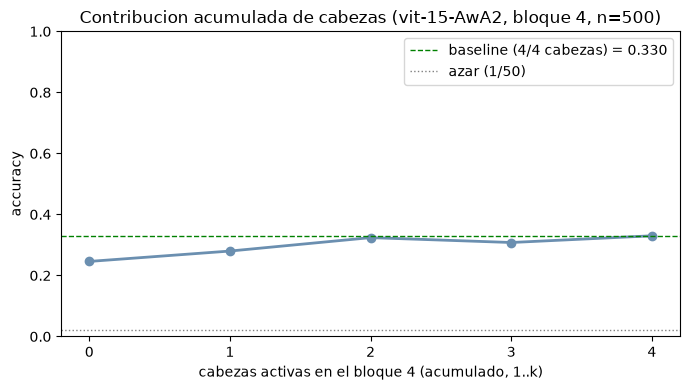

[constrained] k=0: accuracy = 0.198
[constrained] k=1: accuracy = 0.230


[constrained] k=2: accuracy = 0.236
[constrained] k=3: accuracy = 0.284


[constrained] k=4: accuracy = 0.286
guardado: experimentation/experiments/22082026_head_contribution/cumulative_heads_vit-15-constrained-AwA2.png


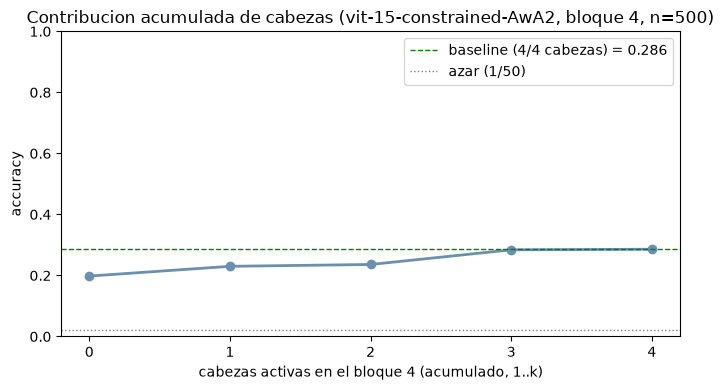

[constrained_rank] k=0: accuracy = 0.306
[constrained_rank] k=1: accuracy = 0.322


[constrained_rank] k=2: accuracy = 0.322
[constrained_rank] k=3: accuracy = 0.330


[constrained_rank] k=4: accuracy = 0.336
guardado: experimentation/experiments/22082026_head_contribution/cumulative_heads_vit-15-constrained_rank-AwA2.png


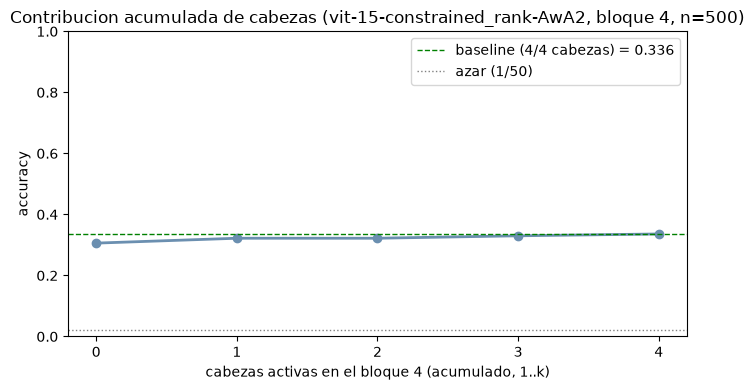

In [6]:
TARGET_LAYER_IDX = n_blocks - 1  # ultimo bloque; cambialo si quieres ver otro

for key, (model, _, _) in models.items():
    cumulative_accuracies = []
    for k in range(0, n_heads + 1):
        logits = forward_with_heads_kept(model, eval_images, target_layer_idx=TARGET_LAYER_IDX, n_heads_kept=k)
        acc = accuracy_of(logits, eval_labels)
        cumulative_accuracies.append(acc)
        print(f"[{key}] k={k}: accuracy = {acc:.3f}")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(0, n_heads + 1), cumulative_accuracies, marker="o", linewidth=2, color="#6b8fb0")
    ax.axhline(baseline_accuracy[key], color="green", linestyle="--", linewidth=1,
               label=f"baseline (4/4 cabezas) = {baseline_accuracy[key]:.3f}")
    ax.axhline(1 / num_classes, color="gray", linestyle=":", linewidth=1, label=f"azar (1/{num_classes})")
    ax.set_xticks(range(0, n_heads + 1))
    ax.set_xlabel(f"cabezas activas en el bloque {TARGET_LAYER_IDX + 1} (acumulado, 1..k)")
    ax.set_ylabel("accuracy")
    ax.set_title(f"Contribucion acumulada de cabezas ({MODELS[key]}, bloque {TARGET_LAYER_IDX + 1}, n={N_EVAL})")
    ax.set_ylim(0, 1)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, "cumulative_heads", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

## 5. Extra: lo mismo, pero en cada bloque

La misma función, generalizada a los 4 bloques — no solo el último. Un heatmap (bloque × cuántas cabezas activas) muestra si el patrón "se arma con pocas cabezas" es igual en todos los bloques o solo pasa en algunos.

guardado: experimentation/experiments/22082026_head_contribution/cumulative_heads_grid_vit-15-AwA2.png


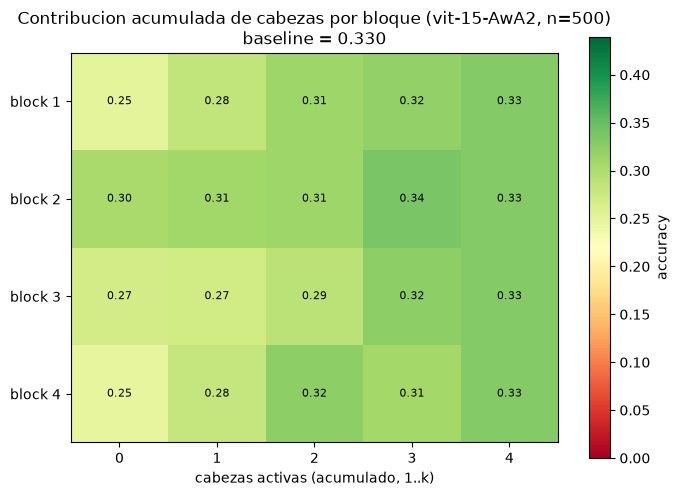

guardado: experimentation/experiments/22082026_head_contribution/cumulative_heads_grid_vit-15-constrained-AwA2.png


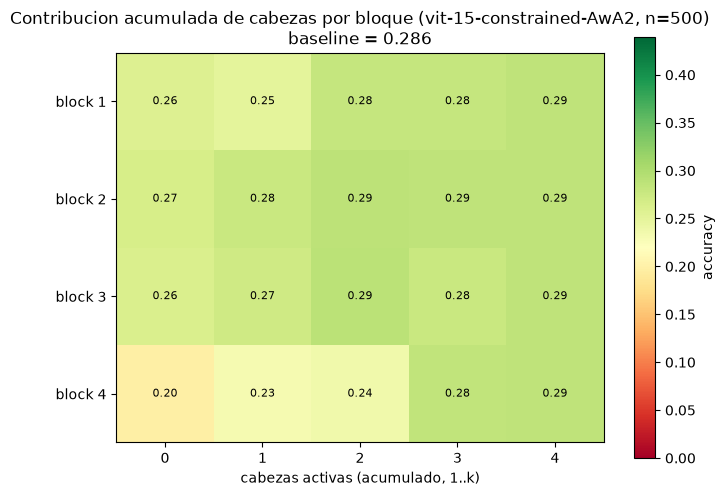

guardado: experimentation/experiments/22082026_head_contribution/cumulative_heads_grid_vit-15-constrained_rank-AwA2.png


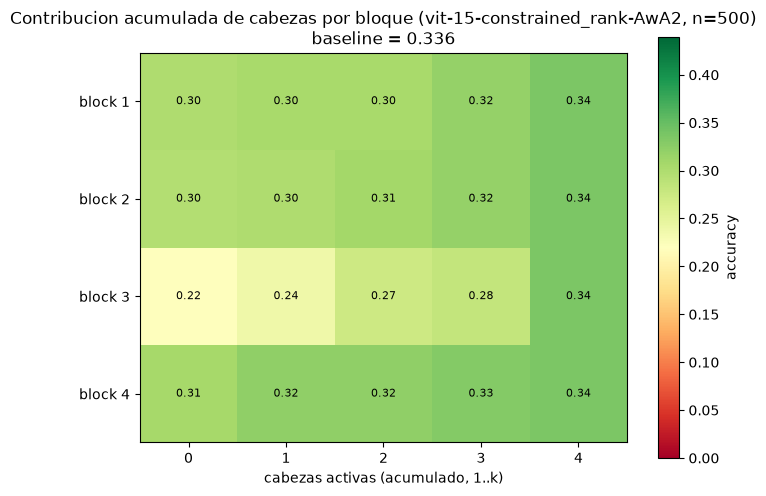

In [7]:
grid_accuracy = {}
for key, (model, _, _) in models.items():
    acc = np.zeros((n_blocks, n_heads + 1))
    for layer_idx in range(n_blocks):
        for k in range(0, n_heads + 1):
            logits = forward_with_heads_kept(model, eval_images, target_layer_idx=layer_idx, n_heads_kept=k)
            acc[layer_idx, k] = accuracy_of(logits, eval_labels)
    grid_accuracy[key] = acc

# Escala de color COMPARTIDA entre modelos: 30% arriba del máximo del baseline (sin
# penalización), para que el mismo color sea comparable entre las dos figuras.
vmax_shared = grid_accuracy["unconstrained"].max() * 1.3

for key in MODELS:
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(grid_accuracy[key], cmap="RdYlGn", vmin=0, vmax=vmax_shared)
    ax.set_xticks(range(n_heads + 1))
    ax.set_xticklabels([str(k) for k in range(n_heads + 1)])
    ax.set_yticks(range(n_blocks))
    ax.set_yticklabels([f"block {l+1}" for l in range(n_blocks)])
    for l in range(n_blocks):
        for k in range(n_heads + 1):
            ax.text(k, l, f"{grid_accuracy[key][l, k]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xlabel("cabezas activas (acumulado, 1..k)")
    ax.set_title(f"Contribucion acumulada de cabezas por bloque ({MODELS[key]}, n={N_EVAL})\nbaseline = {baseline_accuracy[key]:.3f}")
    fig.colorbar(im, ax=ax, label="accuracy")
    plt.tight_layout()
    save_fig(fig, "cumulative_heads_grid", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

## Para reflexionar / siguientes pasos

- En el último bloque, ¿con cuántas cabezas activas ya se acerca a la accuracy baseline? Si con 1-2 cabezas ya casi se llega, esas cabezas concentran la señal que importa para clasificar; si hace falta llegar a 4, la decisión está más repartida.
- ¿El orden 1→2→3→4 importa? Esto suma las cabezas en un orden fijo (1, luego 2, luego 3...) — no es lo mismo que probar todos los órdenes posibles (eso sería un análisis tipo Shapley, más caro). Si el resultado te sorprende, vale la pena probar otro orden (por ejemplo, empezando por la cabeza que salió más crítica en `ablation.ipynb`) para ver si el orden cambia la conclusión.
- Las curvas y heatmaps de baseline e interpretable ya se generan juntos arriba (uno por modelo, guardados por separado): ¿la penalización hace que la curva suba más despacio (cada cabeza aporta un poco) o igual de rápido (unas pocas cabezas siguen dominando)?